# 02 - Train conditional StyleGAN2-ADA (chạy nhiều lần, tự resume)

Dùng repo chính thức `NVlabs/stylegan3` với `--cfg=stylegan2` (StyleGAN2 + ADA, có điều kiện theo 7 lớp).  
GAN chỉ thấy split train (`gan_train.zip` từ notebook 01).

### Cách chạy
| Lần | Việc cần làm |
|---|---|
| **Lần 1** | Add Input: output của `01_prepare_gan_data`. Bật GPU + Internet. Save Version -> Save & Run All. |
| **Lần 2, 3, …** | Add Input thêm: output của chính notebook này (Your Work -> `02_train_gan`). Kiểm tra input trỏ tới version mới nhất. Save & Run All. |

Notebook tự phát hiện có checkpoint cũ hay không: có thì resume, không thì train từ đầu.
Tự dừng sau `MAX_HOURS` giờ (trước giới hạn của Kaggle) để output chắc chắn được lưu.

### Output (`/kaggle/working/checkpoints/`) tích lũy qua các version
```
progress.json                 # tổng kimg, lịch sử từng lần chạy, snapshot mới nhất
network-snapshot-XXXXXX.pkl   # XXXXXX = tổng kimg, giữ KEEP_LAST cái mới nhất + snapshot cuối của mỗi lần chạy
grids/fakesXXXXXX.png         # lưới ảnh mẫu theo tổng kimg
logs/runNN_log.txt, runNN_stats.jsonl, runNN_training_options.json
```

In [ ]:
import os, sys, glob, json, re, shutil, subprocess, time, hashlib

# ===== CONFIG =====
RES            = 256
BATCH          = 32
BATCH_GPU      = 16                         # ảnh/GPU mỗi lượt; T4 x2 -> 2x16 = 32
GAMMA          = round(0.0002 * RES**2 / BATCH, 3)   # heuristic của StyleGAN2-ADA "auto" ~0.41
KIMG_THIS_RUN  = 3000                       # trần số kimg mỗi lần; thường MAX_HOURS dừng trước
MAX_HOURS      = 10.5                       # dừng an toàn trước giới hạn ~12h của Kaggle
SNAP_TICKS     = 10                         # 1 tick = 4 kimg -> snapshot mỗi 40 kimg
KEEP_LAST      = 3                          # snapshot mới nhất giữ lại, ngoài ra luôn giữ snapshot cuối mỗi lần chạy
METRICS        = "none"                     # 'fid50k_full' rất tốn thời gian trên Kaggle -> đánh giá ở notebook 03
SEED           = 0
CBASE          = 16384                      # 16384 = cấu hình "paper256" của StyleGAN2-ADA (~2x nhanh hơn 32768 mặc định)

INPUT_ROOT = "/kaggle/input"
OUT        = "/kaggle/working"
CKPT_DIR   = os.path.join(OUT, "checkpoints")
REPO       = "/tmp/stylegan3"               # để ngoài /kaggle/working cho output gọn
RUN_ROOT   = "/tmp/runs"
for d in [CKPT_DIR, f"{CKPT_DIR}/grids", f"{CKPT_DIR}/logs", RUN_ROOT]:
    os.makedirs(d, exist_ok=True)
print("gamma =", GAMMA)

gamma = 0.41


## 1. Môi trường: GPU, repo StyleGAN3, CUDA ops

In [ ]:
!nvidia-smi --query-gpu=name,memory.total --format=csv
import torch
print("torch", torch.__version__, "| CUDA", torch.version.cuda, "| GPU:", torch.cuda.is_available())
assert torch.cuda.is_available(), "Chưa bật GPU: Settings → Accelerator → GPU"
NUM_GPUS = torch.cuda.device_count()          # Kaggle "GPU T4 x2" -> 2 (nhanh gần gấp đôi so với 1)
assert BATCH % (NUM_GPUS * BATCH_GPU) == 0, (BATCH, NUM_GPUS, BATCH_GPU)
print(f"Dùng {NUM_GPUS} GPU:", [torch.cuda.get_device_name(i) for i in range(NUM_GPUS)])

name, memory.total [MiB]
Tesla T4, 15360 MiB
Tesla T4, 15360 MiB
torch 2.11.0+cu128 | CUDA 12.8 | GPU: True
Dùng 2 GPU: ['Tesla T4', 'Tesla T4']


In [ ]:
if not os.path.exists(REPO):
    !git clone -q https://github.com/NVlabs/stylegan3.git {REPO}
!pip install -q ninja
REPO_COMMIT = subprocess.check_output(["git", "-C", REPO, "rev-parse", "HEAD"]).decode().strip()
print("stylegan3 commit:", REPO_COMMIT)

# Patch nhỏ để resume đúng:
#  - RESUME_KIMG: bộ đếm kimg chạy tiếp từ tổng cũ
#  - RESUME_AUGMENT_P: khôi phục xác suất augment ADA thay vì bắt đầu lại từ 0
train_py = os.path.join(REPO, "train.py")
src = open(train_py).read()
anchor = "        c.loss_kwargs.blur_init_sigma = 0 # Disable blur rampup.\n"
patch = (anchor +
         "        c.resume_kimg = int(os.environ.get('RESUME_KIMG', '0'))\n"
         "        if opts.aug == 'ada': c.augment_p = float(os.environ.get('RESUME_AUGMENT_P', '0'))\n")
if "RESUME_KIMG" not in src:
    assert anchor in src, "train.py đã thay đổi so với bản dự kiến — kiểm tra lại đoạn Resume."
    open(train_py, "w").write(src.replace(anchor, patch))
print("patched:", "RESUME_KIMG" in open(train_py).read())

stylegan3 commit: c233a919a6faee6e36a316ddd4eddababad1adf9
patched: True


In [ ]:
def patch_stylegan3(repo):
    """Vá StyleGAN3 cho Python 3.12+/PyTorch 2.x mới (Kaggle). Chạy lại nhiều lần không sao."""
    import os

    def sub(rel, old, new):
        p = os.path.join(repo, rel)
        s = open(p).read()
        if new in s:
            return "đã vá"
        assert old in s, f"{rel}: không tìm thấy đoạn cần vá; repo đã thay đổi"
        open(p, "w").write(s.replace(old, new))
        return "vá xong"

    report = {}
    # 1) PyTorch mới không thêm thư mục build vào sys.path -> dùng module mà load() trả về
    report["custom_ops: load"] = sub(
        "torch_utils/custom_ops.py",
        "            torch.utils.cpp_extension.load(name=module_name, build_directory=cached_build_dir,",
        "            module = torch.utils.cpp_extension.load(name=module_name, build_directory=cached_build_dir,")
    report["custom_ops: load (else)"] = sub(
        "torch_utils/custom_ops.py",
        "            torch.utils.cpp_extension.load(name=module_name, verbose=verbose_build, sources=sources, **build_kwargs)",
        "            module = torch.utils.cpp_extension.load(name=module_name, verbose=verbose_build, sources=sources, **build_kwargs)")
    report["custom_ops: import"] = sub(
        "torch_utils/custom_ops.py",
        "        module = importlib.import_module(module_name)\n",
        "        if module is None or not hasattr(module, '__name__'):\n"
        "            module = importlib.import_module(module_name)\n")
    # 2) distutils đã bị xoá khỏi Python 3.12+
    report["dnnlib: strtobool"] = sub(
        "dnnlib/util.py",
        "from distutils.util import strtobool\n",
        "def strtobool(v):\n"
        "    v = str(v).lower()\n"
        "    if v in ('y', 'yes', 't', 'true', 'on', '1'): return 1\n"
        "    if v in ('n', 'no', 'f', 'false', 'off', '0'): return 0\n"
        "    raise ValueError(f'invalid truth value {v!r}')\n")
    # 3) pkg_resources đang bị gỡ khỏi setuptools -> dùng packaging
    for rel in ["torch_utils/ops/conv2d_gradfix.py", "torch_utils/ops/grid_sample_gradfix.py"]:
        report[rel] = sub(rel, "from pkg_resources import parse_version",
                          "from packaging.version import parse as parse_version")
    # 4) torch.utils.data.Sampler không còn nhận tham số dataset (PyTorch 2.2+)
    report["misc: InfiniteSampler"] = sub(
        "torch_utils/misc.py",
        "        super().__init__(dataset)\n        self.dataset = dataset",
        "        super().__init__()\n        self.dataset = dataset")
    # 5) API TorchScript nội bộ -> op aten công khai (ADA dùng grid_sample ở mọi bước train)
    report["grid_sample_gradfix: op"] = sub(
        "torch_utils/ops/grid_sample_gradfix.py",
        "        op = torch._C._jit_get_operation('aten::grid_sampler_2d_backward')\n"
        "        if _use_pytorch_1_12_api:\n"
        "            op = op[0]\n",
        "        op = torch.ops.aten.grid_sampler_2d_backward\n")
    report["grid_sample_gradfix: mask"] = sub(
        "torch_utils/ops/grid_sample_gradfix.py",
        "            output_mask = (ctx.needs_input_grad[1], ctx.needs_input_grad[2])",
        "            output_mask = [bool(ctx.needs_input_grad[1]), bool(ctx.needs_input_grad[2])]")
    # 6) tham số only_inputs của autograd.grad đã deprecated (mặc định vẫn là True)
    p = os.path.join(repo, "training/loss.py")
    s = open(p).read()
    report["loss: only_inputs"] = "vá xong" if ", only_inputs=True" in s else "đã vá"
    open(p, "w").write(s.replace(", only_inputs=True", ""))
    return report


FALLBACK_MARK = "# KAGGLE_REF_FALLBACK"

def enable_ref_fallback(repo):
    """Nếu CUDA plugin không build/nạp được: dùng bản PyTorch thuần thay vì dừng (chậm hơn)."""
    import os
    code = (f"\n\n{FALLBACK_MARK}\n"
            "_kaggle_orig_init = _init\n"
            "_kaggle_failed = False\n"
            "def _init():\n"
            "    global _kaggle_failed\n"
            "    if _kaggle_failed:\n"
            "        return False\n"
            "    try:\n"
            "        return _kaggle_orig_init()\n"
            "    except Exception as e:\n"
            "        _kaggle_failed = True\n"
            "        print(f'[fallback] {__name__}: CUDA plugin lỗi ({type(e).__name__}: {e}) -> dùng bản PyTorch thuần')\n"
            "        return False\n")
    for name in ["bias_act", "upfirdn2d", "filtered_lrelu"]:
        p = os.path.join(repo, "torch_utils", "ops", f"{name}.py")
        s = open(p).read()
        if FALLBACK_MARK not in s:
            open(p, "w").write(s + code)



# Vá tương thích Python 3.13 / PyTorch mới của Kaggle + dự phòng PyTorch thuần nếu CUDA plugin lỗi
for k, v in patch_stylegan3(REPO).items():
    print(f"  {k}: {v}")
enable_ref_fallback(REPO)

  custom_ops: load: vá xong
  custom_ops: load (else): vá xong
  custom_ops: import: vá xong
  dnnlib: strtobool: vá xong
  torch_utils/ops/conv2d_gradfix.py: vá xong
  torch_utils/ops/grid_sample_gradfix.py: vá xong
  misc: InfiniteSampler: vá xong
  grid_sample_gradfix: op: vá xong
  grid_sample_gradfix: mask: vá xong
  loss: only_inputs: vá xong


In [ ]:
# Smoke test: build CUDA plugin ngay bây giờ (lỗi sẽ hiện ở đây thay vì sau 10 phút train)
sys.path.insert(0, REPO)
from torch_utils import custom_ops
custom_ops.verbosity = "full"            # in lỗi build đầy đủ nếu có
from torch_utils.ops import bias_act, upfirdn2d
x = torch.randn(4, 8, 16, 16, device="cuda")
b = torch.randn(8, device="cuda")
f = upfirdn2d.setup_filter([1, 3, 3, 1], device="cuda")
y1 = bias_act.bias_act(x, b, act="lrelu")
y2 = upfirdn2d.upfirdn2d(x, f, up=2, padding=1)
# So với bản PyTorch tham chiếu: phải ra cùng kết quả
r1 = bias_act.bias_act(x, b, act="lrelu", impl="ref")
r2 = upfirdn2d.upfirdn2d(x, f, up=2, padding=1, impl="ref")
print("bias_act  max diff:", (y1 - r1).abs().max().item())
print("upfirdn2d max diff:", (y2 - r2).abs().max().item(), "| shape", tuple(y2.shape))
assert torch.allclose(y1, r1, atol=1e-3) and torch.allclose(y2, r2, atol=1e-3), "Kết quả CUDA lệch bản tham chiếu!"
CUDA_OPS = bias_act._plugin is not None and upfirdn2d._plugin is not None
print("CUDA ops:", "OK (bản CUDA nhanh)" if CUDA_OPS else
      "LỖI -> đang dùng bản PyTorch thuần (train vẫn chạy nhưng chậm hơn, xem lỗi phía trên)")

Setting up PyTorch plugin "bias_act_plugin"...
[1/3] /usr/local/cuda/bin/nvcc -MD -MF bias_act.cuda.o.d -DTORCH_EXTENSION_NAME=bias_act_plugin -DTORCH_API_INCLUDE_EXTENSION_H -isystem /usr/local/lib/python3.13/dist-packages/torch/include -isystem /usr/local/lib/python3.13/dist-packages/torch/include/torch/csrc/api/include -isystem /usr/local/cuda/include -isystem /usr/include/python3.13 -D__CUDA_NO_HALF_OPERATORS__ -D__CUDA_NO_HALF_CONVERSIONS__ -D__CUDA_NO_BFLOAT16_CONVERSIONS__ -D__CUDA_NO_HALF2_OPERATORS__ --expt-relaxed-constexpr -gencode=arch=compute_75,code=compute_75 -gencode=arch=compute_75,code=sm_75 --compiler-options '-fPIC' --use_fast_math --allow-unsupported-compiler -std=c++17 -c /root/.cache/torch_extensions/py313_cu128/bias_act_plugin/3cb576a0039689487cfba59279dd6d46-tesla-t4/bias_act.cu -o bias_act.cuda.o 
[2/3] c++ -MMD -MF bias_act.o.d -DTORCH_EXTENSION_NAME=bias_act_plugin -DTORCH_API_INCLUDE_EXTENSION_H -isystem /usr/local/lib/python3.13/dist-packages/torch/include

## 2a. Tìm dữ liệu và checkpoint cũ (nếu có)

In [ ]:
def find(pattern):
    return sorted(glob.glob(os.path.join(INPUT_ROOT, "**", pattern), recursive=True))

zips = find("gan_train.zip")
assert zips, "Không thấy gan_train.zip -> Add Input output của notebook 01_prepare_gan_data."
DATA_ZIP = zips[0]
prep_info = json.load(open(find("prep_info.json")[0]))
print("Data:", DATA_ZIP, "|", prep_info["n_gan_train_images"], "ảnh train | res", prep_info["res"])
assert prep_info["res"] == RES

prev = find("checkpoints/progress.json")
if prev:
    prev_dir = os.path.dirname(prev[0])
    progress = json.load(open(prev[0]))
    # Mang toàn bộ lịch sử (snapshot, lưới ảnh, log) sang output của version này
    shutil.copytree(prev_dir, CKPT_DIR, dirs_exist_ok=True)
    resume_pkl = os.path.join(CKPT_DIR, progress["latest_snapshot"])
    assert os.path.exists(resume_pkl), resume_pkl
    print(f"RESUME từ {progress['latest_snapshot']} | tổng {progress['total_kimg']} kimg | "
          f"augment p = {progress.get('last_augment_p', 0):.3f} | đã chạy {len(progress['runs'])} lần")
else:
    progress = {"total_kimg": 0, "latest_snapshot": None, "last_augment_p": 0.0, "runs": [],
                "config": {"res": RES, "batch": BATCH, "gamma": GAMMA, "cfg": "stylegan2",
                           "cond": True, "mirror": True, "aug": "ada", "seed": SEED, "cbase": CBASE},
                "data_zip_sha256": prep_info["gan_train_zip_sha256"]}
    resume_pkl = None
    print("Không có checkpoint cũ -> TRAIN TỪ ĐẦU")

# Bảo vệ: không đổi kiến trúc giữa các lần resume (snapshot cũ sẽ không khớp)
if resume_pkl:
    assert progress["config"].get("cbase", 32768) == CBASE and progress["config"]["res"] == RES,         f"CBASE/RES khác lần chạy trước ({progress['config']}) -> giữ nguyên cấu hình khi resume."
# Bảo vệ: không resume nhầm sang dữ liệu khác
assert progress["data_zip_sha256"] == prep_info["gan_train_zip_sha256"], "gan_train.zip đã thay đổi so với lúc bắt đầu train!"

Data: /kaggle/input/notebooks/kietvgpham/01-prepare-gan-data/gan_train.zip | 6981 ảnh train | res 256
RESUME từ network-snapshot-002400.pkl | tổng 2400 kimg | augment p = 0.054 | đã chạy 4 lần


## 2b. Chạy thử train 1 kimg (~3-5 phút)

Kiểm tra toàn bộ vòng lặp train (nạp dữ liệu, ADA, R1, lưu snapshot) trước khi chạy 10 tiếng.  
Lỗi ở đây -> notebook dừng ngay, không lãng phí quota GPU.

In [ ]:
SMOKE_DIR = "/tmp/smoke"
shutil.rmtree(SMOKE_DIR, ignore_errors=True)
smoke_cmd = [sys.executable, train_py, f"--outdir={SMOKE_DIR}", "--cfg=stylegan2", f"--data={DATA_ZIP}",
             f"--gpus={NUM_GPUS}", f"--batch={BATCH}", f"--batch-gpu={BATCH_GPU}", f"--gamma={GAMMA}",
             "--cond=True", "--mirror=True", "--aug=ada", "--kimg=1", "--snap=1",
             "--metrics=none", "--workers=2", f"--cbase={CBASE}"]
if resume_pkl:
    smoke_cmd.append(f"--resume={resume_pkl}")   # kiểm tra luôn việc nạp snapshot cũ
t0 = time.time()
r = subprocess.run(smoke_cmd, cwd=REPO, capture_output=True, text=True)
log_tail = (r.stdout + r.stderr).strip().split("\n")[-30:]
print("\n".join(log_tail))
smoke_ok = r.returncode == 0 and bool(glob.glob(f"{SMOKE_DIR}/*/network-snapshot-*.pkl"))
assert smoke_ok, "❌ Chạy thử train THẤT BẠI -> xem log phía trên."
print(f"\n✅ Chạy thử OK ({time.time() - t0:.0f}s) → bắt đầu train thật")
shutil.rmtree(SMOKE_DIR, ignore_errors=True)

b8             -           16       [16, 512, 4, 4]      float32 
mapping.embed  4096        -        [16, 512]            float32 
mapping.fc0    262656      -        [16, 512]            float32 
mapping.fc1    262656      -        [16, 512]            float32 
mapping.fc2    262656      -        [16, 512]            float32 
mapping.fc3    262656      -        [16, 512]            float32 
mapping.fc4    262656      -        [16, 512]            float32 
mapping.fc5    262656      -        [16, 512]            float32 
mapping.fc6    262656      -        [16, 512]            float32 
mapping.fc7    262656      -        [16, 512]            float32 
b4.mbstd       -           -        [16, 513, 4, 4]      float32 
b4.conv        2364416     16       [16, 512, 4, 4]      float32 
b4.fc          4194816     -        [16, 512]            float32 
b4.out         262656      -        [16, 512]            float32 
b4             -           -        [16, 1]              float32 
---       

## 3. Train

Log in ra trực tiếp. Mỗi dòng `tick` cho biết `kimg` (tổng), `sec/kimg` (tốc độ) và `augment` (xác suất ADA).  
Sau lần chạy đầu, dùng `sec/kimg` để ước lượng mỗi lần chạy được bao nhiêu kimg.

In [8]:
start_kimg  = progress["total_kimg"]
target_kimg = start_kimg + KIMG_THIS_RUN
run_no      = len(progress["runs"]) + 1
run_root    = os.path.join(RUN_ROOT, f"run{run_no:02d}")

cmd = [sys.executable, train_py, f"--outdir={run_root}", "--cfg=stylegan2", f"--data={DATA_ZIP}",
       f"--gpus={NUM_GPUS}", f"--batch={BATCH}", f"--batch-gpu={BATCH_GPU}", f"--gamma={GAMMA}",
       "--cond=True", "--mirror=True", "--aug=ada", f"--kimg={target_kimg}",
       f"--snap={SNAP_TICKS}", f"--metrics={METRICS}", f"--seed={SEED}", "--workers=2",
       f"--cbase={CBASE}"]
env = dict(os.environ)
if resume_pkl:
    cmd.append(f"--resume={resume_pkl}")
    env["RESUME_KIMG"] = str(start_kimg)
    env["RESUME_AUGMENT_P"] = str(progress.get("last_augment_p", 0.0))
print(" ".join(cmd))

t0, deadline = time.time(), time.time() + MAX_HOURS * 3600
stopped_by_watchdog = False
proc = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, env=env, cwd=REPO,
                        start_new_session=True)   # để dừng được cả các tiến trình con (mỗi GPU một tiến trình)
for line in proc.stdout:
    print(line, end="")
    if time.time() > deadline:
        print(f"\n>>> Hết {MAX_HOURS}h → dừng train (snapshot gần nhất đã được lưu).")
        stopped_by_watchdog = True
        import signal
        os.killpg(proc.pid, signal.SIGTERM)
        break
try:
    proc.wait(timeout=120)
except subprocess.TimeoutExpired:
    import signal
    os.killpg(proc.pid, signal.SIGKILL)
    proc.wait()
elapsed_h = (time.time() - t0) / 3600
print(f"Return code {proc.returncode} | {elapsed_h:.2f} giờ")

/usr/bin/python3 /tmp/stylegan3/train.py --outdir=/tmp/runs/run05 --cfg=stylegan2 --data=/kaggle/input/notebooks/kietvgpham/01-prepare-gan-data/gan_train.zip --gpus=2 --batch=32 --batch-gpu=16 --gamma=0.41 --cond=True --mirror=True --aug=ada --kimg=5400 --snap=10 --metrics=none --seed=0 --workers=2 --cbase=16384 --resume=/kaggle/working/checkpoints/network-snapshot-002400.pkl

Training options:
{
  "G_kwargs": {
    "class_name": "training.networks_stylegan2.Generator",
    "z_dim": 512,
    "w_dim": 512,
    "mapping_kwargs": {
      "num_layers": 8
    },
    "channel_base": 16384,
    "channel_max": 512,
    "fused_modconv_default": "inference_only"
  },
  "D_kwargs": {
    "class_name": "training.networks_stylegan2.Discriminator",
    "block_kwargs": {
      "freeze_layers": 0
    },
    "mapping_kwargs": {},
    "epilogue_kwargs": {
      "mbstd_group_size": 4
    },
    "channel_base": 16384,
    "channel_max": 512
  },
  "G_opt_kwargs": {
    "class_name": "torch.optim.Adam",
  

## 4. Thu thập snapshot, cập nhật progress.json, dọn bớt file nặng

In [ ]:
run_dirs = sorted(glob.glob(os.path.join(run_root, "*")))
assert run_dirs, "Không có thư mục run -> train lỗi ngay từ đầu, xem log ở trên."
run_dir = run_dirs[-1]

def kimg_of(path):
    return int(re.search(r"(\d{6})\.(pkl|png)$", path).group(1))

new_snaps = [p for p in sorted(glob.glob(f"{run_dir}/network-snapshot-*.pkl")) if kimg_of(p) > start_kimg]
for p in new_snaps:
    shutil.copy2(p, CKPT_DIR)
for p in glob.glob(f"{run_dir}/fakes*.png"):
    shutil.copy2(p, os.path.join(CKPT_DIR, "grids", os.path.basename(p)))
for name in ["log.txt", "stats.jsonl", "training_options.json"]:
    if os.path.exists(f"{run_dir}/{name}"):
        shutil.copy2(f"{run_dir}/{name}", f"{CKPT_DIR}/logs/run{run_no:02d}_{name}")

# Xác suất augment cuối cùng (để lần sau resume tiếp đúng giá trị)
last_p = progress.get("last_augment_p", 0.0)
if os.path.exists(f"{run_dir}/stats.jsonl"):
    for line in open(f"{run_dir}/stats.jsonl"):
        rec = json.loads(line)
        if "Progress/augment" in rec:
            last_p = rec["Progress/augment"]["mean"]

if new_snaps:
    reached = kimg_of(new_snaps[-1])          # chỉ tính phần đã được lưu vào snapshot
    progress["total_kimg"] = reached
    progress["latest_snapshot"] = os.path.basename(new_snaps[-1])
else:
    reached = start_kimg
    print("Không có snapshot mới -> lần chạy quá ngắn hoặc bị lỗi. progress giữ nguyên.")
progress["last_augment_p"] = last_p
progress["runs"].append({
    "run": run_no, "date": time.strftime("%Y-%m-%d %H:%M"), "hours": round(elapsed_h, 2),
    "resumed_from": os.path.basename(resume_pkl) if resume_pkl else None,
    "kimg_start": start_kimg, "kimg_end": reached, "augment_p_end": round(last_p, 4),
    "stopped_by_watchdog": stopped_by_watchdog, "return_code": proc.returncode,
    "stylegan3_commit": REPO_COMMIT, "gpu": f"{NUM_GPUS}x {torch.cuda.get_device_name(0)}", "cuda_ops": CUDA_OPS,
})

# Giữ KEEP_LAST snapshot mới nhất + snapshot cuối của mỗi lần chạy (mốc để so sánh / quay lại nếu chất lượng giảm)
snaps = sorted(glob.glob(f"{CKPT_DIR}/network-snapshot-*.pkl"), key=kimg_of)
milestones = {r["kimg_end"] for r in progress["runs"]}
keep = set(snaps[-KEEP_LAST:]) | {p for p in snaps if kimg_of(p) in milestones}
for p in snaps:
    if p not in keep:
        os.remove(p)
progress["kept_snapshots"] = [os.path.basename(p) for p in sorted(keep, key=kimg_of)]
json.dump(progress, open(f"{CKPT_DIR}/progress.json", "w"), indent=2)

print(json.dumps({k: progress[k] for k in ["total_kimg", "latest_snapshot", "last_augment_p", "kept_snapshots"]}, indent=2))
print(f"Output: {sum(os.path.getsize(p) for p in glob.glob(f'{CKPT_DIR}/**', recursive=True) if os.path.isfile(p)) / 1e9:.2f} GB")

# Báo lỗi rõ ràng: train hỏng mà không phải do watchdog dừng -> version này phải hiện là lỗi
if proc.returncode != 0 and not stopped_by_watchdog:
    raise RuntimeError(f"train.py lỗi (return code {proc.returncode}) -> xem log ở cell train. "
                       f"Snapshot đã lưu đến: {progress['latest_snapshot']}")

{
  "total_kimg": 3320,
  "latest_snapshot": "network-snapshot-003320.pkl",
  "last_augment_p": 0.0639999732375145,
  "kept_snapshots": [
    "network-snapshot-000520.pkl",
    "network-snapshot-001000.pkl",
    "network-snapshot-001480.pkl",
    "network-snapshot-002400.pkl",
    "network-snapshot-003240.pkl",
    "network-snapshot-003280.pkl",
    "network-snapshot-003320.pkl"
  ]
}
Output: 5.82 GB


## 5. Xem tiến triển: lưới ảnh sinh qua các mốc kimg

fakes003280.png


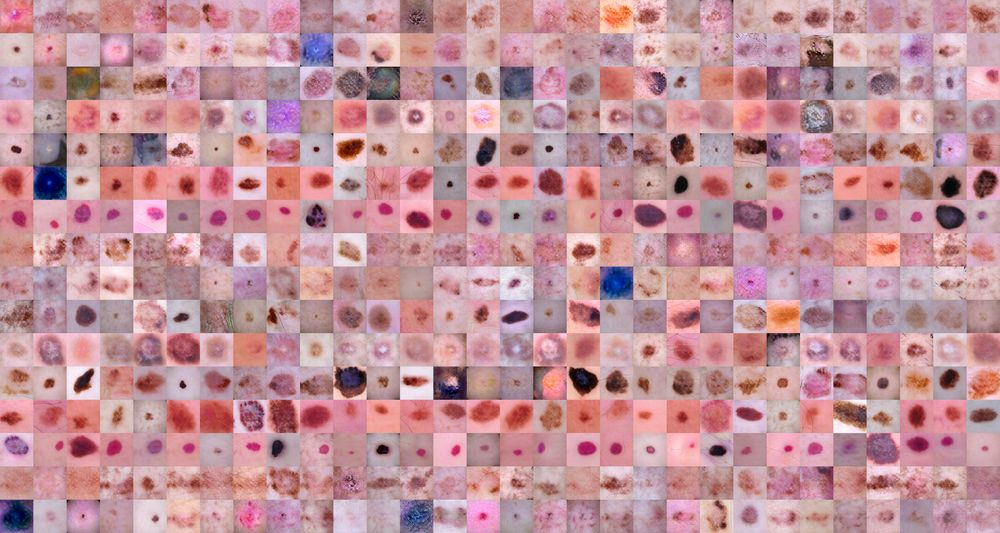

fakes003320.png


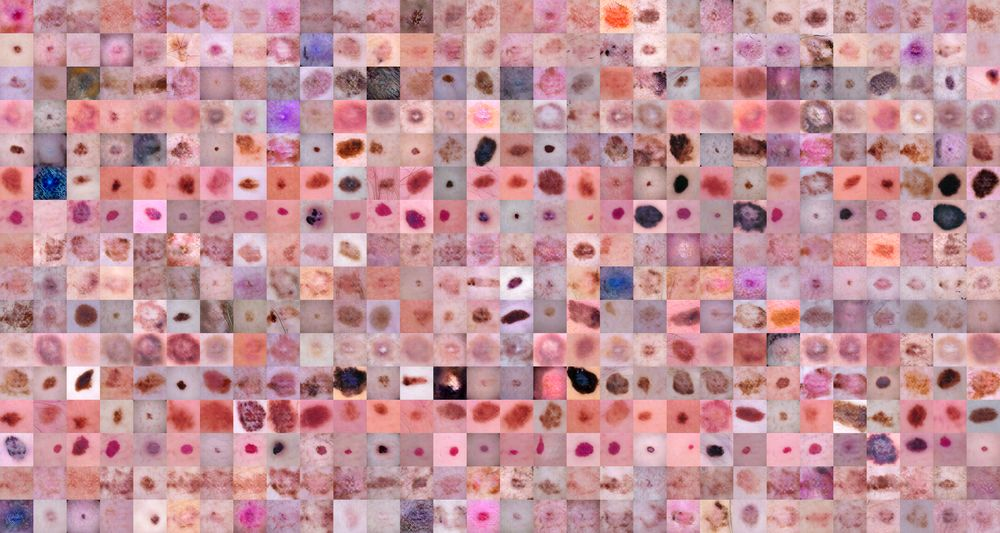

In [ ]:
import io
from PIL import Image as PILImage
from IPython.display import Image as IPImage, display

# Chỉ hiện bản thu nhỏ (JPEG ~1000px) để file notebook đầu ra nhẹ, ảnh gốc vẫn ở checkpoints/grids/
def show_small(path, width=1000):
    im = PILImage.open(path).convert("RGB")
    im = im.resize((width, round(im.height * width / im.width)), PILImage.LANCZOS)
    buf = io.BytesIO(); im.save(buf, format="JPEG", quality=80)
    display(IPImage(data=buf.getvalue()))

grids = sorted(glob.glob(f"{CKPT_DIR}/grids/fakes*.png"), key=lambda p: kimg_of(p) if re.search(r"\d{6}", p) else -1)
show = grids[-2:]          # 2 mốc mới nhất, xem các mốc cũ trong tab Output
for g in show:
    print(os.path.basename(g))
    show_small(g)